# Level 2 — Task 4: Restaurant Chains

### Identifying Chains & Analysing Their Ratings and Popularity

This dataset contains 9,551 restaurant listings scraped from a Zomato-style
platform, covering cuisine type, cost, ratings, and location across multiple
cities and countries.

**Business question:** Which restaurant chains are present, and do chains earn
better ratings and more customer attention than independent restaurants?

**Objectives:**
1. Identify whether there are any restaurant chains in the dataset.
2. Analyze the ratings and popularity of the different chains.

## 1. Dataset Overview

In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Note: filename has a trailing space as saved in the data folder

In [2]:
df = pd.read_csv("../../data/Dataset .csv")
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
df.shape

(9551, 21)

## 2. Data Quality Assessment

In [4]:
print("Missing Restaurant Name values:", df["Restaurant Name"].isna().sum())
print("Duplicate Restaurant IDs:", df["Restaurant ID"].duplicated().sum())
print("Unique restaurant names:", df["Restaurant Name"].nunique(), "of", len(df), "listings")

unrated = (df["Aggregate rating"] == 0).sum()
print(f"Unrated restaurants (rating = 0): {unrated} ({unrated / len(df) * 100:.2f}%)")

Missing Restaurant Name values: 0
Duplicate Restaurant IDs: 0
Unique restaurant names: 7446 of 9551 listings
Unrated restaurants (rating = 0): 2148 (22.49%)


Every row is a separate outlet (no duplicate Restaurant IDs), and names are
fully populated. The dataset has **no "chain" column**, so chains must be
detected from the names: when the same brand appears at many outlets, it is
treated as a chain.

A rating of `0` means **"Not rated"**, not a bad restaurant, so unrated
outlets are excluded when average ratings are calculated.

## 3. Identifying Restaurant Chains

### Standardising restaurant names

The same brand can be written in different ways (for example "Giani" and
"Giani's", "Dunkin' Donuts" and "Dunkin Donuts", or "Cafe Coffee Day" and
"Cafe Coffee Day - The Lounge"). Counting these as separate names would split
one chain into several small ones. A cleaned `Brand` name is created using these
rules: lowercase, drop any text after " - ", remove the possessive "'s", remove
punctuation, and remove the word "the".

In [5]:
def clean_brand(name):
    s = name.lower()
    s = re.sub(r"\s+[-–]\s+.*$", "", s)
    s = re.sub(r"[’']s\b", "", s)
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    s = re.sub(r"\bthe\b", "", s)
    return re.sub(r"\s+", " ", s).strip()

df["Brand"] = df["Restaurant Name"].map(clean_brand)
display_name = df.groupby("Brand")["Restaurant Name"].agg(lambda s: s.mode()[0])

print("Unique restaurant names:", df["Restaurant Name"].nunique())
print("Unique brands after cleaning:", df["Brand"].nunique())
print("Empty brand names:", (df["Brand"] == "").sum())

Unique restaurant names: 7446
Unique brands after cleaning: 7312
Empty brand names: 0


In [6]:
variants = df.groupby("Brand")["Restaurant Name"].agg(lambda s: sorted(set(s)))
variants = variants[variants.apply(len) > 1]

brand_size = df["Brand"].value_counts()
examples = variants[variants.index.isin(brand_size[brand_size >= 5].index)].apply(lambda v: " | ".join(v[:3]))
examples.head(12)

Brand
aggarwal sweets                      Aggarwal Sweets | Aggarwal's Sweets
beer cafe                         The Beer Cafe | The Beer Cafe - BIGGIE
burger king                                  Burger King | Burger's King
cafe coffee day           Cafe Coffee Day | Cafe Coffee Day - The Lounge
chawla                                    Chawla | Chawla's | Chawla's�_
china town                                   China Town | The China Town
chinese hut                                Chinese Hut | The Chinese Hut
dunkin donuts                             Dunkin Donuts | Dunkin' Donuts
frontier                                 Frontier | Frontier - The Ashok
giani                                                    Giani | Giani's
great kabab factory    The Great Kabab Factory | The Great Kabab Fact...
hot pot                                              Hot & Pot | Hot Pot
Name: Restaurant Name, dtype: object

In [7]:
brand_counts = df["Brand"].value_counts()

thresholds = pd.DataFrame({"Min Outlets with Same Brand": [2, 5, 10, 20]})
thresholds["Chain Brands"] = thresholds["Min Outlets with Same Brand"].apply(lambda t: (brand_counts >= t).sum())
thresholds["Outlets Covered"] = thresholds["Min Outlets with Same Brand"].apply(lambda t: brand_counts[brand_counts >= t].sum())
thresholds["% of All Listings"] = (thresholds["Outlets Covered"] / len(df) * 100).round(2)
thresholds

,Min Outlets with Same Brand,Chain Brands,Outlets Covered,% of All Listings
0,2,799,3038,31.81
1,5,116,1447,15.15
2,10,41,982,10.28
3,20,14,585,6.13


Brands that appear only 2 to 4 times may be coincidences (different restaurants
sharing a common name), so a **chain is defined as a brand with 5 or more
outlets**. Restaurants with 2 to 4 outlets are kept as a separate "small
repeat" group, and the rest are "single outlet" restaurants.

In [8]:
MIN_OUTLETS = 5
chain_names = brand_counts[brand_counts >= MIN_OUTLETS].index

df["Restaurant Type"] = np.where(
    df["Brand"].isin(chain_names), "Chain (5+ outlets)",
    np.where(df["Brand"].map(brand_counts) >= 2, "Small repeat (2-4 outlets)", "Single outlet"),
)

type_counts = df["Restaurant Type"].value_counts()
type_table = pd.DataFrame({
    "Restaurant Type": type_counts.index,
    "Restaurants": type_counts.values,
    "Percentage": (type_counts.values / len(df) * 100).round(2),
})
type_table

,Restaurant Type,Restaurants,Percentage
0,Single outlet,6513,68.19
1,Small repeat (2-4 outlets),1591,16.66
2,Chain (5+ outlets),1447,15.15


In [9]:
chain_stats = (
    df[df["Brand"].isin(chain_names)].groupby("Brand")
    .agg(Outlets=("Restaurant ID", "size"),
         Cities=("City", "nunique"),
         Rated_Outlets=("Aggregate rating", lambda s: (s > 0).sum()),
         Avg_Rating=("Aggregate rating", lambda s: s[s > 0].mean()),
         Total_Votes=("Votes", "sum"),
         Avg_Votes_per_Outlet=("Votes", "mean"))
    .sort_values("Outlets", ascending=False)
    .round(2)
)
chain_stats.index = chain_stats.index.map(display_name)
chain_stats.index.name = "Chain"
chain_stats.head(15)

,Outlets,Cities,Rated_Outlets,Avg_Rating,Total_Votes,Avg_Votes_per_Outlet
Chain,,,,,,
Cafe Coffee Day,89,5,73,2.98,2758,30.99
Domino's Pizza,79,7,74,2.93,6643,84.09
Subway,63,5,61,3.00,6124,97.21
Green Chick Chop,51,4,44,3.10,964,18.90
Giani,51,4,42,3.31,2004,39.29
McDonald's,48,7,47,3.41,5291,110.23
Keventers,34,4,29,3.37,1263,37.15
Pizza Hut,30,12,29,3.43,4961,165.37
Baskin Robbins,28,5,16,3.26,428,15.29


In [10]:
print(f"Chains found (brands with {MIN_OUTLETS}+ outlets): {len(chain_stats)}")
print(f"Outlets belonging to chains: {chain_stats['Outlets'].sum():,} ({chain_stats['Outlets'].sum() / len(df) * 100:.2f}% of all listings)")
print(f"Largest chain: {chain_stats.index[0]} with {chain_stats.iloc[0]['Outlets']:.0f} outlets")

Chains found (brands with 5+ outlets): 116
Outlets belonging to chains: 1,447 (15.15% of all listings)
Largest chain: Cafe Coffee Day with 89 outlets


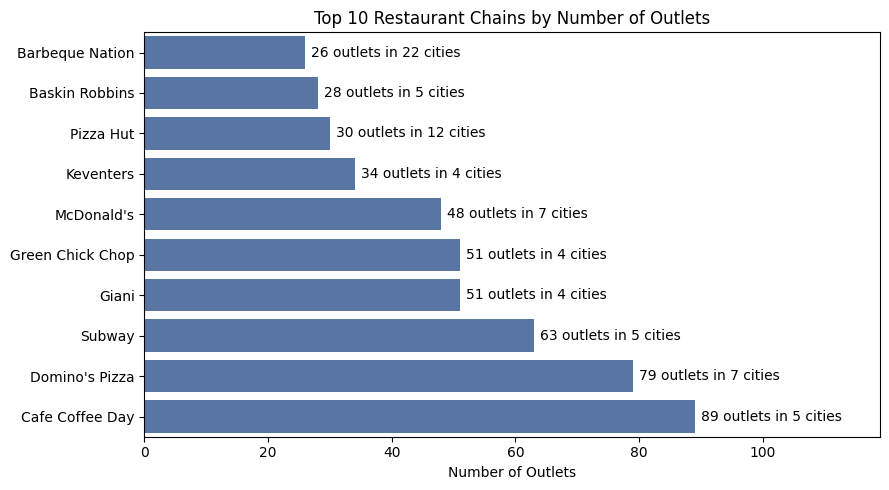

In [11]:
top10 = chain_stats.head(10).sort_values("Outlets")

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=top10["Outlets"], y=top10.index, color="#4C72B0")
for i, (v, c) in enumerate(zip(top10["Outlets"], top10["Cities"])):
    ax.text(v + 1, i, f"{v:.0f} outlets in {c:.0f} cities", va="center")
plt.xlim(0, top10["Outlets"].max() + 30)
plt.title("Top 10 Restaurant Chains by Number of Outlets")
plt.xlabel("Number of Outlets")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 4. Ratings: Chains vs Other Restaurants

In [12]:
rated_df = df[df["Aggregate rating"] > 0]

def compare_types(data):
    rated = data[data["Aggregate rating"] > 0]
    out = data.groupby("Restaurant Type").agg(
        Restaurants=("Restaurant ID", "size"),
        Unrated_Pct=("Aggregate rating", lambda s: (s == 0).mean() * 100),
        Avg_Votes=("Votes", "mean"),
        Median_Votes=("Votes", "median"),
    )
    out["Avg_Rating_Rated"] = rated.groupby("Restaurant Type")["Aggregate rating"].mean()
    out["Median_Rating_Rated"] = rated.groupby("Restaurant Type")["Aggregate rating"].median()
    return out.round(2).loc[["Chain (5+ outlets)", "Small repeat (2-4 outlets)", "Single outlet"]]

compare_types(df)

,Restaurants,Unrated_Pct,Avg_Votes,Median_Votes,Avg_Rating_Rated,Median_Rating_Rated
Restaurant Type,,,,,,
Chain (5+ outlets),1447,13.68,149.90,46.0,3.25,3.3
Small repeat (2-4 outlets),1591,18.86,203.96,43.0,3.43,3.4
Single outlet,6513,25.33,146.97,25.0,3.49,3.4


Nearly all chain outlets are in India, while single-outlet restaurants include
many abroad, where ratings are higher. To make the comparison fair, it is
repeated for India only.

In [13]:
india = df[df["Currency"].str.contains("Indian")]
chain_total = df["Brand"].isin(chain_names).sum()
print(f"India share of all listings: {len(india) / len(df) * 100:.2f}% | "
      f"of chain outlets: {india['Brand'].isin(chain_names).sum() / chain_total * 100:.2f}%")

compare_types(india)

India share of all listings: 90.59% | of chain outlets: 99.10%


,Restaurants,Unrated_Pct,Avg_Votes,Median_Votes,Avg_Rating_Rated,Median_Rating_Rated
Restaurant Type,,,,,,
Chain (5+ outlets),1434,13.81,148.31,45.0,3.24,3.3
Small repeat (2-4 outlets),1502,19.91,190.40,37.0,3.38,3.4
Single outlet,5716,28.73,120.45,18.0,3.38,3.3


### Robustness check: does cleaning the names change the conclusions?

In [14]:
def summarize(col):
    counts = df[col].map(df[col].value_counts())
    chain_flag = counts >= 5
    rated = df["Aggregate rating"] > 0
    return {
        "Chains": f"{df.loc[chain_flag, col].nunique():,}",
        "Chain outlets": f"{int(chain_flag.sum()):,}",
        "% of listings": f"{chain_flag.mean() * 100:.2f}%",
        "Avg rating: chains": f"{df.loc[chain_flag & rated, 'Aggregate rating'].mean():.2f}",
        "Avg rating: single outlet": f"{df.loc[(counts == 1) & rated, 'Aggregate rating'].mean():.2f}",
    }

pd.DataFrame({"Exact name": summarize("Restaurant Name"), "Cleaned brand": summarize("Brand")})

,Exact name,Cleaned brand
Chains,112,116
Chain outlets,"1,395","1,447"
% of listings,14.61%,15.15%
Avg rating: chains,3.24,3.25
Avg rating: single outlet,3.49,3.49


In [15]:
MIN_RATED = 10
reliable = chain_stats[chain_stats["Rated_Outlets"] >= MIN_RATED].sort_values("Avg_Rating", ascending=False)
overall_rated_avg = rated_df["Aggregate rating"].mean()

print(f"Chains with at least {MIN_RATED} rated outlets: {len(reliable)} of {len(chain_stats)}")
print(f"Chains rated below the overall average ({overall_rated_avg:.2f}): {(reliable['Avg_Rating'] < overall_rated_avg).sum()} of {len(reliable)}")

print("\nHighest-rated chains:")
display(reliable.head(8)[["Outlets", "Rated_Outlets", "Avg_Rating", "Avg_Votes_per_Outlet"]])
print("Lowest-rated chains:")
display(reliable.tail(8)[["Outlets", "Rated_Outlets", "Avg_Rating", "Avg_Votes_per_Outlet"]])

Chains with at least 10 rated outlets: 36 of 116
Chains rated below the overall average (3.44): 27 of 36

Highest-rated chains:


,Outlets,Rated_Outlets,Avg_Rating,Avg_Votes_per_Outlet
Chain,,,,
Barbeque Nation,26,26,4.35,1082.38
Starbucks,18,18,3.81,396.61
Chaayos,18,17,3.75,137.39
Dunkin' Donuts,24,21,3.67,256.75
Haldiram's,16,16,3.62,282.81
Burger Point,11,10,3.46,52.18
Burger King,17,17,3.45,283.29
Costa Coffee,20,14,3.45,43.05


Lowest-rated chains:


,Outlets,Rated_Outlets,Avg_Rating,Avg_Votes_per_Outlet
Chain,,,,
Sagar Ratna,19,19,2.96,212.53
Domino's Pizza,79,74,2.93,84.09
Pind Balluchi,20,18,2.92,279.10
KFC,18,17,2.91,129.50
Republic of Chicken,18,15,2.91,13.00
Pizza Hut Delivery,19,18,2.81,80.37
Chicago Pizza,12,10,2.79,52.75
Wah Ji Wah,19,17,2.62,54.00


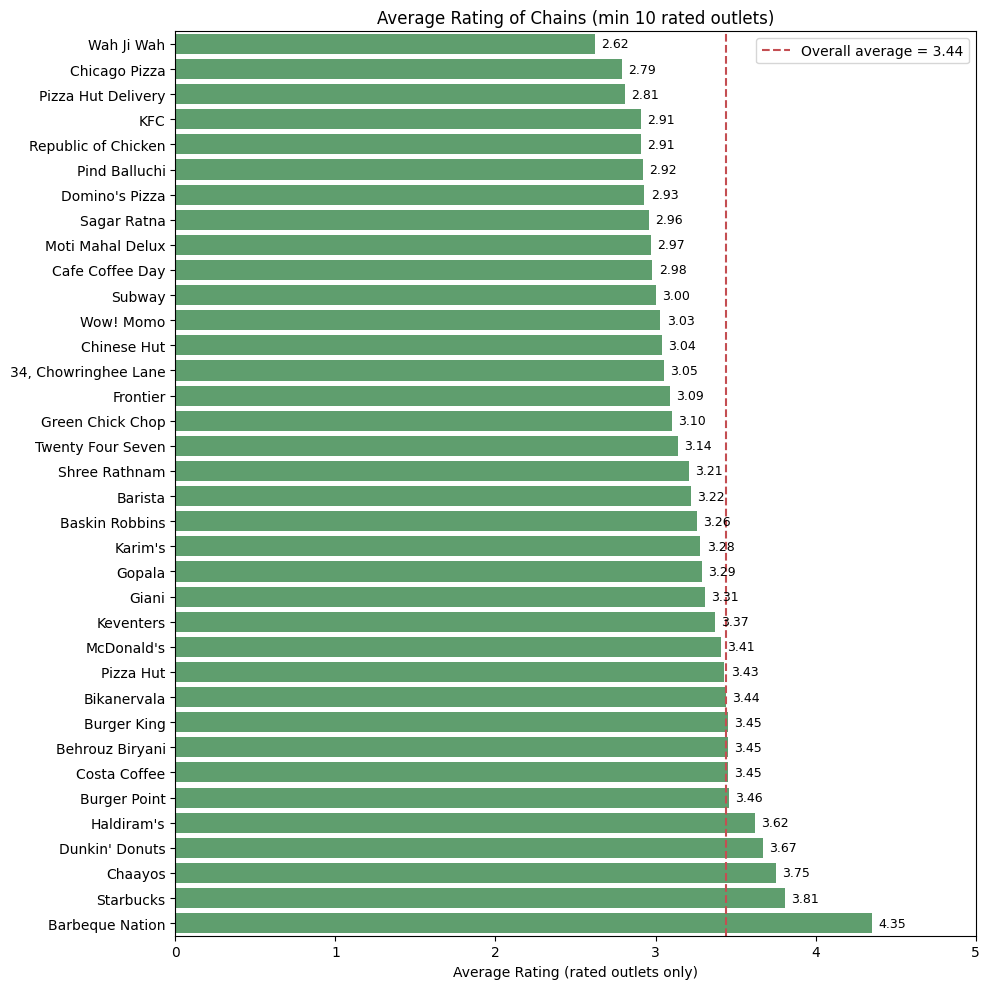

In [16]:
plot_r = reliable.sort_values("Avg_Rating")

plt.figure(figsize=(10, 10))
ax = sns.barplot(x=plot_r["Avg_Rating"], y=plot_r.index, color="#55A868")
for i, v in enumerate(plot_r["Avg_Rating"]):
    ax.text(v + 0.04, i, f"{v:.2f}", va="center", fontsize=9)
plt.axvline(overall_rated_avg, color="#C44E52", linestyle="--", label=f"Overall average = {overall_rated_avg:.2f}")
plt.xlim(0, 5)
plt.title(f"Average Rating of Chains (min {MIN_RATED} rated outlets)")
plt.xlabel("Average Rating (rated outlets only)")
plt.ylabel("")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Popularity of Chains

Popularity is measured with `Votes` (customer engagement). **Total votes** shows
how much attention a whole chain gets, and **votes per outlet** shows how
popular a typical outlet is.

In [17]:
popular = chain_stats.sort_values("Total_Votes", ascending=False)
popular.head(10)[["Outlets", "Total_Votes", "Avg_Votes_per_Outlet", "Avg_Rating"]]

,Outlets,Total_Votes,Avg_Votes_per_Outlet,Avg_Rating
Chain,,,,
Barbeque Nation,26,28142,1082.38,4.35
Farzi Cafe,6,10098,1683.00,4.37
Chili's,5,8156,1631.20,4.58
Starbucks,18,7139,396.61,3.81
Pirates of Grill,5,7132,1426.40,4.00
Karim's,13,6878,529.08,3.28
Domino's Pizza,79,6643,84.09,2.93
Dunkin' Donuts,24,6162,256.75,3.67
Subway,63,6124,97.21,3.00


In [18]:
total_chain_votes = chain_stats["Total_Votes"].sum()
print(f"Votes received by all chain outlets: {total_chain_votes:,}")
print(f"Top 5 chains by votes hold {popular['Total_Votes'].head(5).sum() / total_chain_votes * 100:.2f}% of them")
print(f"{popular.index[0]} alone holds {popular['Total_Votes'].iloc[0] / total_chain_votes * 100:.2f}%")

Votes received by all chain outlets: 216,904
Top 5 chains by votes hold 27.97% of them
Barbeque Nation alone holds 12.97%


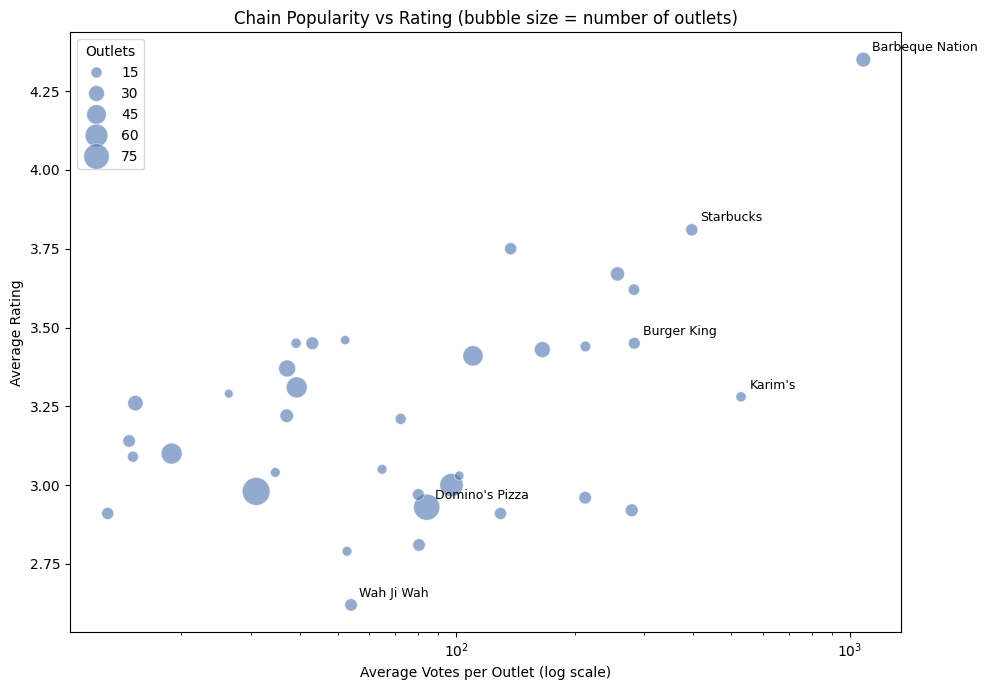

In [19]:
plot_p = chain_stats[chain_stats["Rated_Outlets"] >= MIN_RATED].copy()

plt.figure(figsize=(10, 7))
sns.scatterplot(data=plot_p, x="Avg_Votes_per_Outlet", y="Avg_Rating", size="Outlets",
                sizes=(40, 400), alpha=0.6, color="#4C72B0", legend="brief")
plt.xscale("log")

labels = plot_p.sort_values("Avg_Votes_per_Outlet", ascending=False).head(4).index.tolist() + ["Domino's Pizza", "Wah Ji Wah"]
for name in labels:
    row = plot_p.loc[name]
    plt.annotate(name, (row["Avg_Votes_per_Outlet"], row["Avg_Rating"]),
                 xytext=(6, 6), textcoords="offset points", fontsize=9)

plt.title("Chain Popularity vs Rating (bubble size = number of outlets)")
plt.xlabel("Average Votes per Outlet (log scale)")
plt.ylabel("Average Rating")
plt.tight_layout()
plt.show()

In [20]:
plot_p[["Avg_Rating", "Avg_Votes_per_Outlet", "Outlets"]].corr(method="spearman").round(2)

,Avg_Rating,Avg_Votes_per_Outlet,Outlets
Avg_Rating,1.00,0.32,-0.03
Avg_Votes_per_Outlet,0.32,1.00,-0.03
Outlets,-0.03,-0.03,1.00


## 6. How Chains Differ from Other Restaurants

In [21]:
order = ["Chain (5+ outlets)", "Small repeat (2-4 outlets)", "Single outlet"]

delivery = df.groupby("Restaurant Type")["Has Online delivery"].apply(lambda s: (s == "Yes").mean() * 100).round(1).rename("Online Delivery (%)")
price_mix = pd.crosstab(df["Restaurant Type"], df["Price range"], normalize="index").mul(100).round(1)
price_mix.columns = [f"Price range {c} (%)" for c in price_mix.columns]

pd.concat([delivery, price_mix], axis=1).loc[order]

,Online Delivery (%),Price range 1 (%),Price range 2 (%),Price range 3 (%),Price range 4 (%)
Restaurant Type,,,,,
Chain (5+ outlets),39.0,44.6,42.6,10.6,2.1
Small repeat (2-4 outlets),37.3,43.9,36.0,14.8,5.3
Single outlet,19.8,47.6,29.5,15.6,7.2


In [22]:
spread = (
    rated_df[rated_df["Brand"].isin(chain_names)].groupby("Brand")["Aggregate rating"]
    .agg(Rated_Outlets="count", Rating_Std="std")
)
spread = spread[spread["Rated_Outlets"] >= MIN_RATED].sort_values("Rating_Std").round(2)
spread.index = spread.index.map(display_name)

print(f"Average spread of ratings between outlets of the same chain: {spread['Rating_Std'].mean():.2f}")
print("\nMost consistent chains:")
display(spread.head(3))
print("Least consistent chains:")
display(spread.tail(3))

Average spread of ratings between outlets of the same chain: 0.34

Most consistent chains:


,Rated_Outlets,Rating_Std
Brand,,
Republic of Chicken,15,0.15
Dunkin' Donuts,21,0.18
Twenty Four Seven,13,0.19


Least consistent chains:


,Rated_Outlets,Rating_Std
Brand,,
KFC,17,0.52
Sagar Ratna,19,0.53
Pizza Hut,29,0.59


## 7. Final Results

In [23]:
type_rating = compare_types(df)["Avg_Rating_Rated"]

task_result = pd.DataFrame({
    "Question": [
        "Chains found (brands with 5+ outlets)",
        "Outlets belonging to chains",
        "Largest chain",
        "Highest-rated chain (min 10 rated outlets)",
        "Lowest-rated chain (min 10 rated outlets)",
        "Most-voted chain",
        "Avg rating: chains vs single-outlet restaurants",
    ],
    "Answer": [
        len(chain_stats),
        f"{chain_stats['Outlets'].sum():,} ({chain_stats['Outlets'].sum() / len(df) * 100:.2f}% of all listings)",
        f"{chain_stats.index[0]} ({chain_stats.iloc[0]['Outlets']:.0f} outlets)",
        f"{reliable.index[0]} ({reliable.iloc[0]['Avg_Rating']:.2f})",
        f"{reliable.index[-1]} ({reliable.iloc[-1]['Avg_Rating']:.2f})",
        f"{popular.index[0]} ({popular.iloc[0]['Total_Votes']:,.0f} votes)",
        f"{type_rating['Chain (5+ outlets)']:.2f} vs {type_rating['Single outlet']:.2f}",
    ],
})
task_result

,Question,Answer
0,Chains found (brands with 5+ outlets),116
1,Outlets belonging to chains,"1,447 (15.15% of all listings)"
2,Largest chain,Cafe Coffee Day (89 outlets)
3,Highest-rated chain (min 10 rated outlets),Barbeque Nation (4.35)
4,Lowest-rated chain (min 10 rated outlets),Wah Ji Wah (2.62)
5,Most-voted chain,"Barbeque Nation (28,142 votes)"
6,Avg rating: chains vs single-outlet restaurants,3.25 vs 3.49


## 8. Validation

In [24]:
print("Restaurant types add up to total:", type_counts.sum() == len(df))
print("Chain outlets match chain table:", chain_stats["Outlets"].sum() == type_counts["Chain (5+ outlets)"])
print("Rated + unrated = total:", len(rated_df) + unrated == len(df))

Restaurant types add up to total: True
Chain outlets match chain table: True
Rated + unrated = total: True


### Business Insights

**Are there chains?**

- **Yes. After cleaning the names, 116 brands appear at 5 or more outlets**,
  covering 1,447 listings (15.15% of the dataset). Counting every brand that
  repeats at least twice gives 799 brands and 3,038 listings (31.81%), but small
  repeats may be coincidences.
- **The largest chains are Cafe Coffee Day (89 outlets), Domino's Pizza (79),
  Subway (63), Green Chick Chop (51) and Giani (51).** The widest footprint
  belongs to Barbeque Nation (26 outlets in 22 cities), followed by Pizza Hut
  (30 outlets in 12 cities).
- **Cleaning the names did not change the story.** Using exact names gives 112
  chains and 1,395 outlets (14.61%); using cleaned brands gives 116 chains and
  1,447 outlets (15.15%). The average ratings are the same to within 0.01.

**Ratings**

- **Chains are rated lower than independent restaurants.** Rated chain outlets
  average **3.25**, versus 3.49 for single-outlet restaurants and 3.44 overall.
  The gap remains when only India is compared (3.24 versus 3.38).
- **27 of the 36 chains with at least 10 rated outlets score below the overall
  average of 3.44.** The biggest chains are mid-to-low: Cafe Coffee Day 2.98,
  Subway 3.00, Domino's 2.93 and McDonald's 3.41.
- **The best chain is Barbeque Nation (4.35)**, followed by Starbucks (3.81),
  Chaayos (3.75), Dunkin' Donuts (3.67) and Haldiram's (3.62). The weakest are
  Wah Ji Wah (2.62), Chicago Pizza (2.79) and Pizza Hut Delivery (2.81).
- **Being bigger does not mean being better.** Across the 36 chains, the number
  of outlets has almost no link with rating (rank correlation -0.03).
- **Quality is uneven inside some chains.** Outlets of Republic of Chicken
  (spread 0.15) and Dunkin' Donuts (0.18) are rated very consistently, while
  Pizza Hut (0.59), Sagar Ratna (0.53) and KFC (0.52) vary much more from outlet
  to outlet.

**Popularity**

- **Chain outlets are better known than independents.** Only 13.68% of chain
  outlets are unrated versus 25.33% of single-outlet restaurants, and the median
  chain outlet has 46 votes versus 25 (45 versus 18 within India). The *average*
  votes are similar (150 versus 147) because a few independent restaurants
  attract very many votes.
- **Votes are concentrated in a few chains.** Barbeque Nation alone holds
  28,142 votes (12.97% of all chain votes), and the top five (Barbeque Nation,
  Farzi Cafe, Chili's, Starbucks, Pirates of Grill) hold 27.97%.
- **Popularity depends on quality, not on size.** Domino's has 79 outlets but
  only 84 votes per outlet, while Chili's (4.58 rating) and Farzi Cafe (4.37)
  average over 1,600 votes per outlet with just 5 to 6 outlets. Across chains,
  rating and votes per outlet are moderately linked (rank correlation 0.32).

**Chain profile**

- **Chains offer online delivery twice as often:** 39.0% versus 19.8% for
  single-outlet restaurants.
- **Chains focus on affordable pricing.** 87.2% of chain outlets are in price
  ranges 1 and 2 (versus 77.1% for single-outlet restaurants), and only 2.1% are
  in the premium range 4 (versus 7.2%).

**Caution**

- There is no chain column, so chains are detected from the **name only**. The
  name cleaning merges spelling variants, but it cannot merge every variant
  (for example Pizza Hut and Pizza Hut Delivery stay separate), and its
  "drop text after ' - '" rule can occasionally merge different concepts that
  share a first word. Generic names (for example "Chinese Corner") may also
  belong to unrelated restaurants.
- The 5-outlet threshold is a choice, and the dataset samples about 20
  restaurants for most cities, so outlet counts reflect this dataset and not
  the real size of a chain.
- 99.10% of chain outlets are in India, so findings mainly describe the
  Indian market.
- 2,148 unrated restaurants (rating 0) are excluded from average ratings.
- These are associations, not causes. The data does not show why chains rate
  lower.